<a href="https://colab.research.google.com/github/vivekpandey0706/AMR-2026/blob/main/MNIST_CNN_Digit_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   # MNIST digit recognition: MLP vs CNN
   A fully connected network and a small convolutional neural network trained on MNIST in PyTorch, compared on the same test set, with an analysis of the mistakes the CNN still makes.

In [15]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("running on", device)

running on cuda


In [16]:
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
# the image pixel mean and standdard deviation of the 60000 training images

to_normalized_tensor = transforms.Compose( [
    transforms.ToTensor()  ,

    transforms.Normalize((MNIST_MEAN,), (MNIST_STD,)),
])

full_train_set = datasets.MNIST("data", train=True, download=True, transform=to_normalized_tensor)
test_set = datasets.MNIST("data", train=False, download=True, transform=to_normalized_tensor)

# Dividing the data into training set and validation set
train_set, val_set = random_split(full_train_set, [55_000,5_000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=1000)
test_loader = DataLoader(test_set, batch_size=1000)

print(len(train_set), len(val_set), len(test_set))

55000 5000 10000


torch.Size([64, 1, 28, 28]) torch.float32 torch.Size([64]) torch.int64
pixel mean -0.00, std 1.00
training images per digit: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


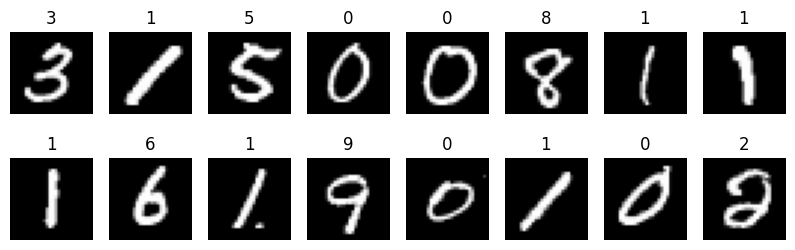

In [17]:
images, labels = next(iter(train_loader))
print(images.shape, images.dtype, labels.shape, labels.dtype)

print(f"pixel mean {images.mean():.2f}, std {images.std():.2f}")

digit_counts = torch.bincount(full_train_set.targets, minlength=10)
print("training images per digit:", digit_counts.tolist())


fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for axis, image, label in zip(axes.flat, images, labels):
    axis.imshow(image.squeeze() * MNIST_STD + MNIST_MEAN, cmap="gray")
    axis.set_title(label.item())
    axis.axis("off")
plt.savefig("sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
class MLPBaseline(nn.Module):
    # reducing the 28x28 image grid into 784 numbers then in next layer into 256 ReLU units and finally in output layer as 10 digit scores
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 10),
        )

    def forward(self, images):
        return self.layers(images)


class DigitCNN(nn.Module):

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.dropout_after_pool = nn.Dropout(0.25)

        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.dropout_after_fc1 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, images):
        x = F.relu(self.conv1(images))
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, kernel_size=2)
        x = self.dropout_after_pool(x).flatten(start_dim=1)
        x = self.dropout_after_fc1(F.relu(self.fc1(x)))
        return self.fc2(x)


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())


print(f"MLP parameters: {count_parameters(MLPBaseline()):,}")
print(f"CNN parameters: {count_parameters(DigitCNN()):,}")

shape_check = DigitCNN().eval()
x = torch.zeros(1, 1, 28, 28)
x = F.relu(shape_check.conv1(x)); print("after conv1:", tuple(x.shape))
x = F.relu(shape_check.conv2(x)); print("after conv2:", tuple(x.shape))
x = F.max_pool2d(x, 2);  print("after pool: ", tuple(x.shape))
x = x.flatten(start_dim=1);  print("flattened:  ", tuple(x.shape))

MLP parameters: 203,530
CNN parameters: 1,199,882
after conv1: (1, 32, 26, 26)
after conv2: (1, 64, 24, 24)
after pool:  (1, 64, 12, 12)
flattened:   (1, 9216)


In [19]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += F.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += len(labels)
    return total_loss / seen, correct / seen


def train(model, epochs=8, learning_rate=1e-3, decay_per_epoch=0.7):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=decay_per_epoch)

    history = []
    best_val_accuracy, best_weights = 0.0, None
    for epoch in range(1, epochs + 1):
        model.train()
        start = time.time()
        running_loss, batches = 0.0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            loss = F.cross_entropy(model(images), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            batches += 1
        scheduler.step()

        val_loss, val_accuracy = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": running_loss / batches,
                        "val_loss": val_loss, "val_accuracy": val_accuracy})
        print(f"epoch {epoch}  train loss {running_loss / batches:.4f}  "
              f"val loss {val_loss:.4f}  val accuracy {val_accuracy:.2%}  ({time.time() - start:.0f}s)")

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_weights = {name: tensor.detach().clone() for name, tensor in model.state_dict().items()}

    model.load_state_dict(best_weights)
    print(f"kept the best epoch: val accuracy {best_val_accuracy:.2%}")
    return history

In [20]:
def overfit_one_batch(model, steps=200):

    model.to(device)
    images, labels = next(iter(train_loader))
    images, labels = images.to(device), labels.to(device)

    model.eval()
    with torch.no_grad():
        first_loss = F.cross_entropy(model(images), labels).item()

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    model.train()
    for step in range(steps):
        loss = F.cross_entropy(model(images), labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        final_loss = F.cross_entropy(model(images), labels).item()
        accuracy = (model(images).argmax(dim=1) == labels).float().mean().item()
    return first_loss, final_loss, accuracy


for model_class in [MLPBaseline, DigitCNN]:
    first, final, accuracy = overfit_one_batch(model_class())
    print(f"{model_class.__name__:12s} loss before {first:.3f} (ln 10 = 2.303), after {final:.4f}, accuracy {accuracy:.0%}")


MLPBaseline  loss before 2.295 (ln 10 = 2.303), after 0.0005, accuracy 100%
DigitCNN     loss before 2.318 (ln 10 = 2.303), after 0.0000, accuracy 100%


In [21]:
torch.manual_seed(42)
mlp = MLPBaseline()
mlp_history = train(mlp, epochs=8)


epoch 1  train loss 0.2357  val loss 0.1530  val accuracy 95.38%  (17s)
epoch 2  train loss 0.0937  val loss 0.1089  val accuracy 96.50%  (13s)
epoch 3  train loss 0.0591  val loss 0.0869  val accuracy 97.36%  (12s)
epoch 4  train loss 0.0407  val loss 0.0769  val accuracy 97.66%  (13s)
epoch 5  train loss 0.0303  val loss 0.0721  val accuracy 97.88%  (12s)
epoch 6  train loss 0.0236  val loss 0.0693  val accuracy 97.98%  (12s)
epoch 7  train loss 0.0192  val loss 0.0695  val accuracy 97.90%  (12s)
epoch 8  train loss 0.0165  val loss 0.0680  val accuracy 97.96%  (12s)
kept the best epoch: val accuracy 97.98%


In [22]:
torch.manual_seed(42)
cnn = DigitCNN()
cnn_history = train(cnn, epochs=8)


epoch 1  train loss 0.2182  val loss 0.0562  val accuracy 98.38%  (13s)
epoch 2  train loss 0.0787  val loss 0.0516  val accuracy 98.42%  (13s)
epoch 3  train loss 0.0568  val loss 0.0454  val accuracy 98.74%  (14s)
epoch 4  train loss 0.0426  val loss 0.0387  val accuracy 98.88%  (13s)
epoch 5  train loss 0.0340  val loss 0.0370  val accuracy 98.98%  (13s)
epoch 6  train loss 0.0282  val loss 0.0362  val accuracy 99.06%  (14s)
epoch 7  train loss 0.0245  val loss 0.0384  val accuracy 99.04%  (13s)
epoch 8  train loss 0.0225  val loss 0.0364  val accuracy 99.20%  (14s)
kept the best epoch: val accuracy 99.20%


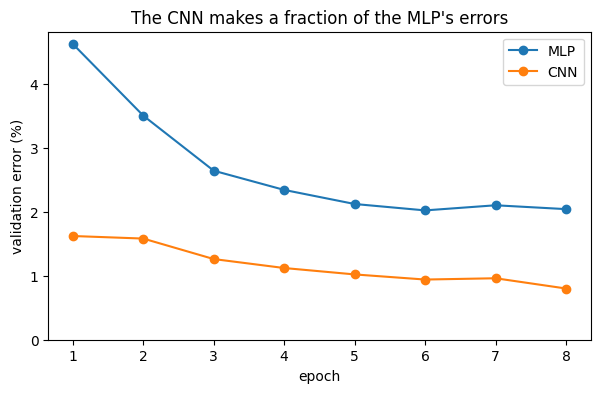

In [23]:
plt.figure(figsize=(7, 4))
for history, name in [(mlp_history, "MLP"), (cnn_history, "CNN")]:
    epochs = [entry["epoch"] for entry in history]
    error_rates = [100 * (1 - entry["val_accuracy"]) for entry in history]
    plt.plot(epochs, error_rates, marker="o", label=name)
plt.ylim(bottom=0)
plt.xlabel("epoch")
plt.ylabel("validation error (%)")
plt.title("The CNN makes a fraction of the MLP's errors")
plt.legend()
plt.savefig("validation_error.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
#testing set
print("| Model | Parameters | Test accuracy | Test errors (of 10,000) |")
print("| --- | --- | --- | --- |")
for model, name in [(mlp, "MLP 784-256-10"), (cnn, "CNN, two 3x3 convolutions")]:
    test_loss, test_accuracy = evaluate(model, test_loader)
    errors = round((1 - test_accuracy) * len(test_set))
    print(f"| {name} | {count_parameters(model):,} | {test_accuracy:.2%} | {errors} |")


| Model | Parameters | Test accuracy | Test errors (of 10,000) |
| --- | --- | --- | --- |
| MLP 784-256-10 | 203,530 | 98.11% | 189 |
| CNN, two 3x3 convolutions | 1,199,882 | 99.17% | 83 |


digit 0: 99.59% correct, 4 mistakes
digit 1: 99.74% correct, 3 mistakes
digit 2: 99.22% correct, 8 mistakes
digit 3: 99.41% correct, 6 mistakes
digit 4: 98.98% correct, 10 mistakes
digit 5: 99.22% correct, 7 mistakes
digit 6: 98.96% correct, 10 mistakes
digit 7: 99.03% correct, 10 mistakes
digit 8: 99.18% correct, 8 mistakes
digit 9: 98.32% correct, 17 mistakes

most common mix-ups (count, true -> predicted):
  6x  4 -> 9
  5x  7 -> 2
  5x  5 -> 3
  4x  9 -> 8
  4x  6 -> 0
  4x  2 -> 7
  3x  9 -> 7
  3x  9 -> 4


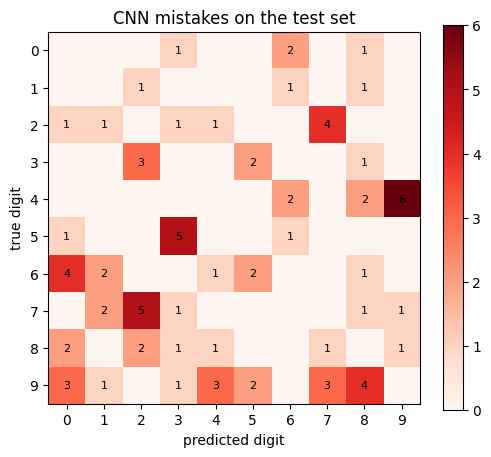

In [25]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    predictions, true_labels = [], []
    for images, labels in loader:
        predictions.append(model(images.to(device)).argmax(dim=1).cpu())
        true_labels.append(labels)
    return torch.cat(predictions), torch.cat(true_labels)


cnn_predictions, test_labels = predict_all(cnn, test_loader)

confusion = torch.zeros((10, 10), dtype=torch.long)
for true_digit, predicted_digit in zip(test_labels.tolist(), cnn_predictions.tolist()):
    confusion[true_digit, predicted_digit] += 1

per_digit_accuracy = confusion.diag() / confusion.sum(dim=1)
for digit in range(10):
    mistakes = confusion[digit].sum().item() - confusion[digit, digit].item()


    print(f"digit {digit}: {per_digit_accuracy[digit]:.2%} correct, {mistakes} mistakes")

mix_ups = [(confusion[t, p].item(), t, p) for t in range(10) for p in range(10) if t != p and confusion[t, p] > 0]

print("\nmost common mix-ups (count, true -> predicted):")
for count, true_digit, predicted_digit in sorted(mix_ups, reverse=True)[:8]:
    print(f"  {count}x  {true_digit} -> {predicted_digit}")


mistakes_only = confusion.clone()
mistakes_only.fill_diagonal_(0)
plt.figure(figsize=(6, 5))
plt.imshow(mistakes_only, cmap="Reds")
for t in range(10):
    for p in range(10):
        if mistakes_only[t, p] > 0:
            plt.text(p, t, mistakes_only[t, p].item(), ha="center", va="center", fontsize=8)
plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("predicted digit")
plt.ylabel("true digit")
plt.title("CNN mistakes on the test set")
plt.colorbar()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")

plt.show()

83 misclassified test images


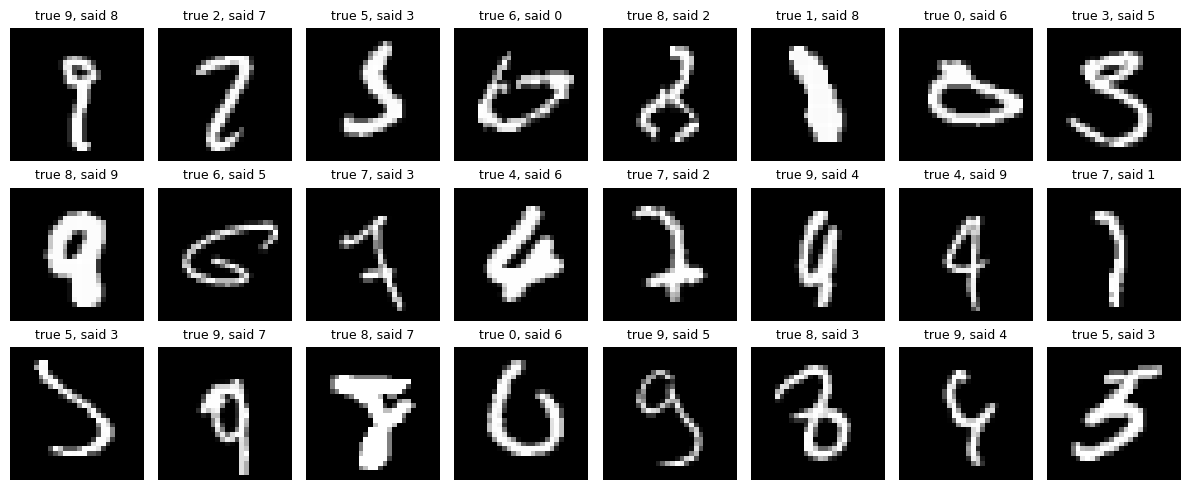

In [26]:
wrong_indices = (cnn_predictions != test_labels).nonzero().flatten().tolist()
print(len(wrong_indices), "misclassified test images")

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for axis, index in zip(axes.flat, wrong_indices[:24]):
    image, true_digit = test_set[index]
    axis.imshow(image.squeeze() * MNIST_STD + MNIST_MEAN, cmap="gray")
    axis.set_title(f"true {true_digit}, said {cnn_predictions[index].item()}", fontsize=9)
    axis.axis("off")
plt.tight_layout()
plt.savefig("misclassified_digits.png", dpi=150, bbox_inches="tight")
plt.show()

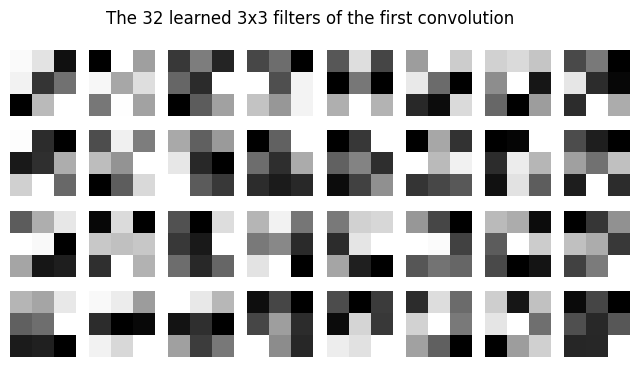

In [27]:
first_layer_filters = cnn.conv1.weight.detach().cpu()
fig, axes = plt.subplots(4, 8, figsize=(8, 4))
for axis, kernel in zip(axes.flat, first_layer_filters):

    axis.imshow(kernel.squeeze(), cmap="gray")
    axis.axis("off")
plt.suptitle("The 32 learned 3x3 filters of the first convolution")


plt.savefig("first_layer_filters.png", dpi=150, bbox_inches="tight")
plt.show()


MLP ['98.1%', '89.4%', '54.4%', '21.3%', '6.0%']
CNN ['99.2%', '96.7%', '75.3%', '38.0%', '11.3%']


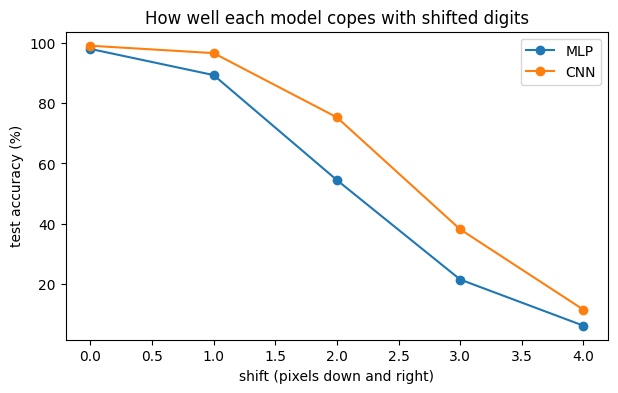

In [28]:
@torch.no_grad()
def accuracy_on_shifted_digits(model, shift):

    model.eval()
    correct = 0
    for images, labels in test_loader:
        shifted = torch.roll(images, shifts=(shift, shift), dims=(2, 3))
        correct += (model(shifted.to(device)).argmax(dim=1).cpu() == labels).sum().item()
    return correct / len(test_set)


shifts = [0, 1, 2, 3, 4]
plt.figure(figsize=(7, 4))
for model, name in [(mlp, "MLP"), (cnn, "CNN")]:
    accuracies = [accuracy_on_shifted_digits(model, shift) for shift in shifts]
    print(name, [f"{accuracy:.1%}" for accuracy in accuracies])
    plt.plot(shifts, [100 * accuracy for accuracy in accuracies], marker="o", label=name)
plt.xlabel("shift (pixels down and right)")
plt.ylabel("test accuracy (%)")
plt.title("How well each model copes with shifted digits")

plt.legend()
plt.savefig("shift_test.png", dpi=150, bbox_inches="tight")
plt.show()
